<center>
<h1> Machine Learning para la toma de deciones </h1>

<b> John González </b>

23 de febrero de 2023
<p>
<img src='https://cdni.iconscout.com/illustration/premium/thumb/man-making-decision-7658820-6182536.png' height=200/>
</center>

Pycaret es una librería de Python que permite trabajar con Machine Learning con bajo código. A diferencia de otras librerías como sklearn, keras, pytorch, fast.ai, ... Esta permite tener varios modelos de una manera muy rápida. Por debajo utiliza principalmente la libraría sklearn, básicamente Pycaret lo que hace es simplificar su uso.

Nosotros en este notebook vamos a seguir [este tutorial](https://pycaret.gitbook.io/docs/get-started/quickstart)

Vamos a instalar la última versión (no estable) de PyCaret. La versión estable en este momento es la 2.3 pero tiene conflictos con los paquetes preinstalados en Google Colab.

In [ ]:
! pip install pycaret

Adicionalmente vamos a instalar sweetviz, una librería especializada para hacer análisis descriptivo exploratorio para machine learning.

In [ ]:
! pip install sweetviz

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.1/15.1 MB 67.9 MB/s eta 0:00:00


Después de instalar los paquetes necesarios es buena práctica reiniciar el entorno de ejecución (click en el Menú: Entorno de ejecución -> Reiniciar entorno de ejecución)

## 1. Importar datos

In [ ]:
from pycaret.datasets import get_data
data = get_data('diabetes')
print('Dimensiones de la tabla:', data.shape)

,Number of times pregnant,Plasma glucose concentration a 2 hours in an oral glucose tolerance test,Diastolic blood pressure (mm Hg),Triceps skin fold thickness (mm),2-Hour serum insulin (mu U/ml),Body mass index (weight in kg/(height in m)^2),Diabetes pedigree function,Age (years),Class variable
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


Dimensiones de la tabla: (768, 9)


## 2. Análisis Descriptivo Exploratorio (EDA)

Es obligatorio entender los datos antes que cualquier otra cosa. Responder preguntas como:
1. Las variables tiene valores nulos?
2. Cuál es el comportamiento de cada variable? Tienen sesgo?
3. Cómo se relaciona cada variable frente a la variable objetivo?
4. Cómo se relacionan entre sí las variables? Mapa de correlación

                                             |          | [  0%]   00:00 -> (? left)


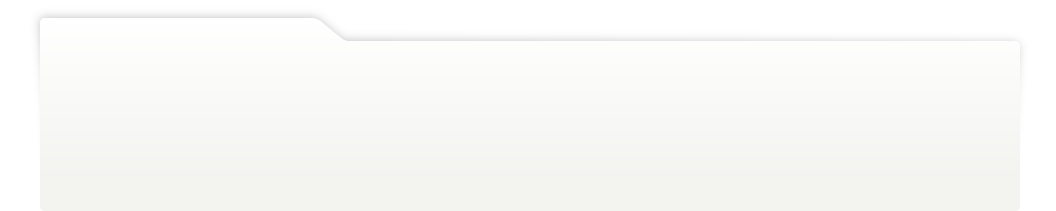
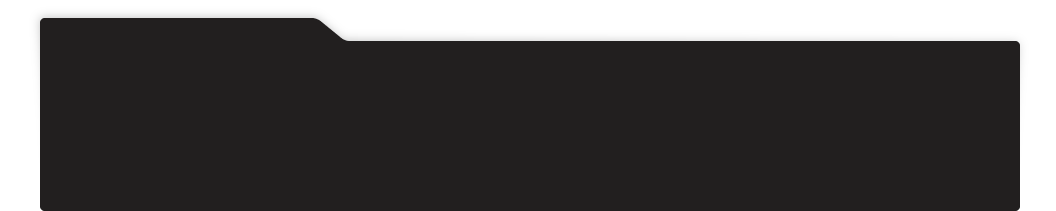
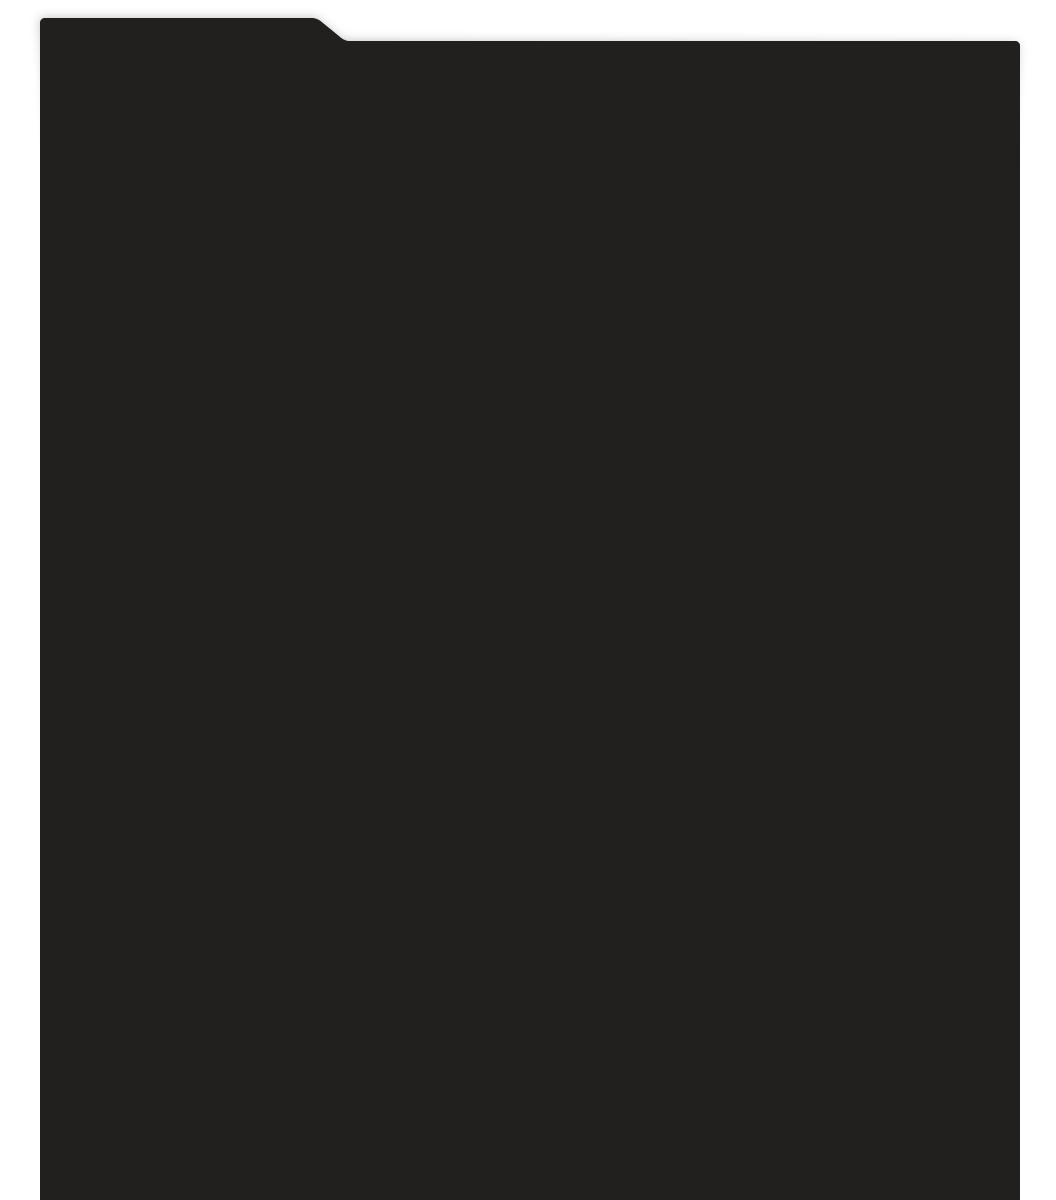
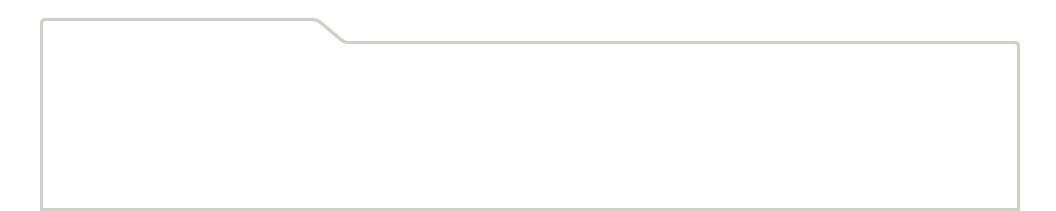
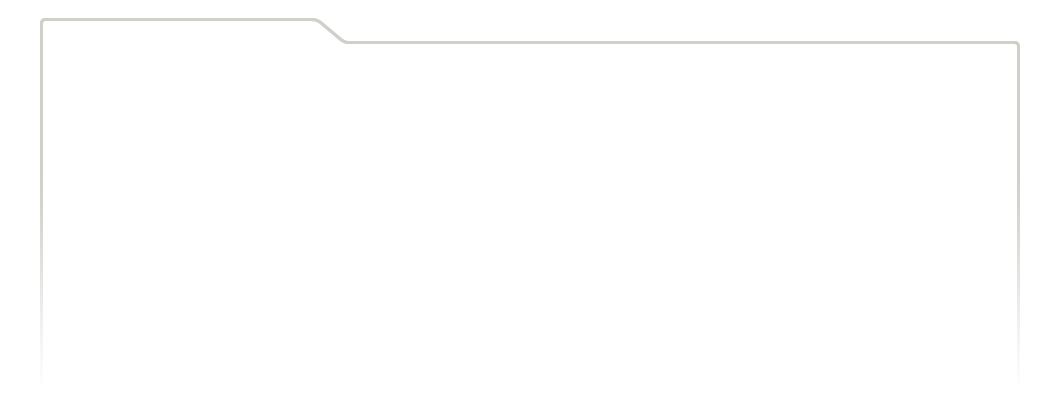
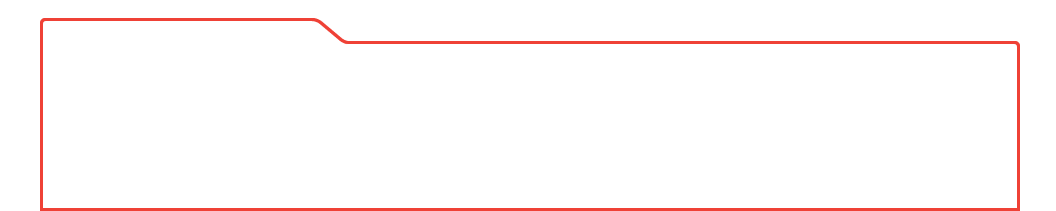
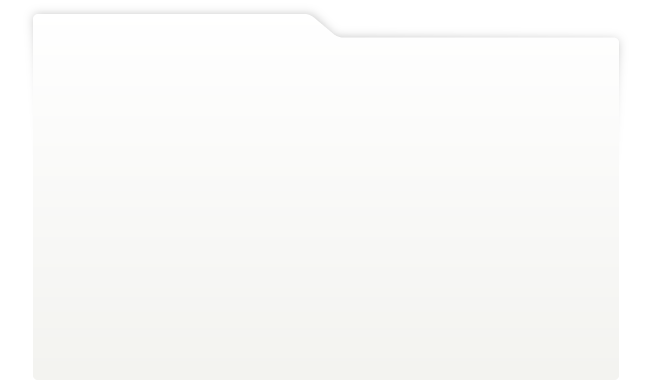
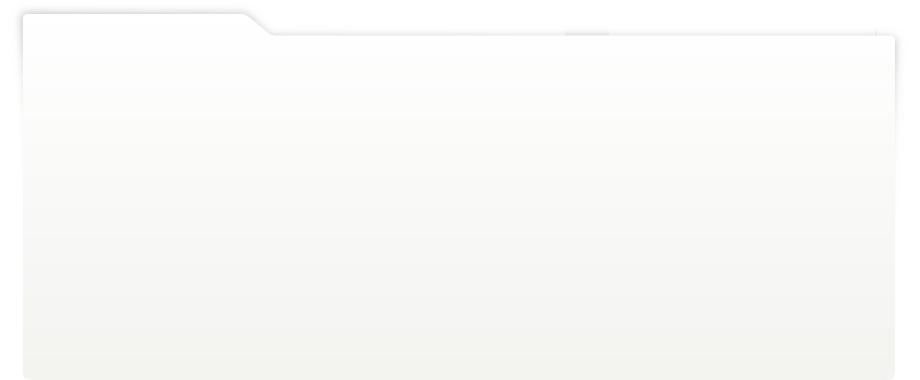
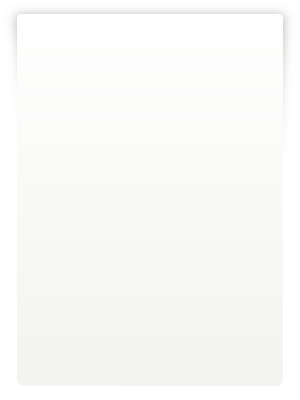
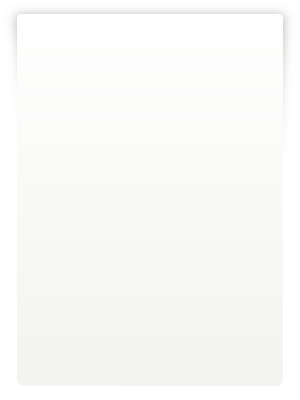
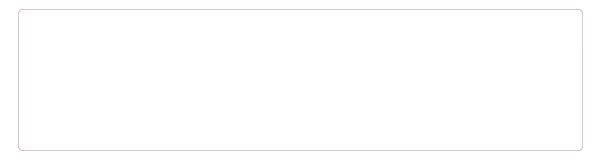
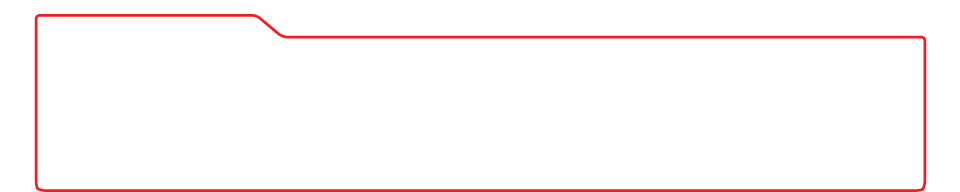
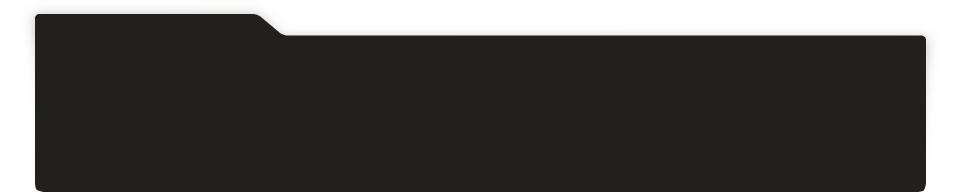
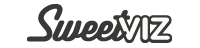
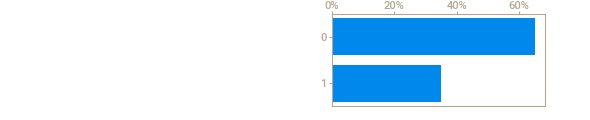
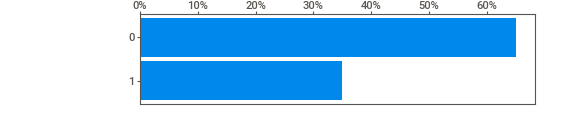
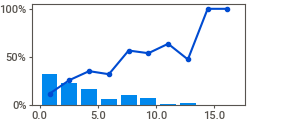
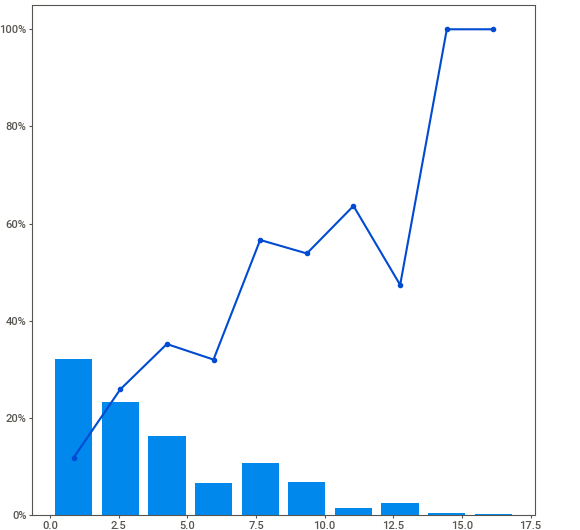
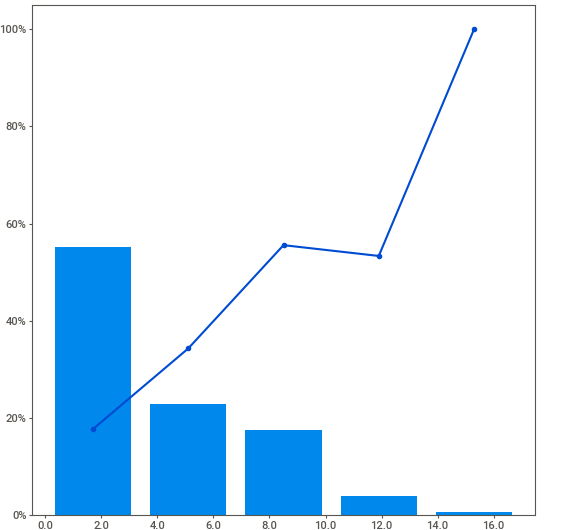
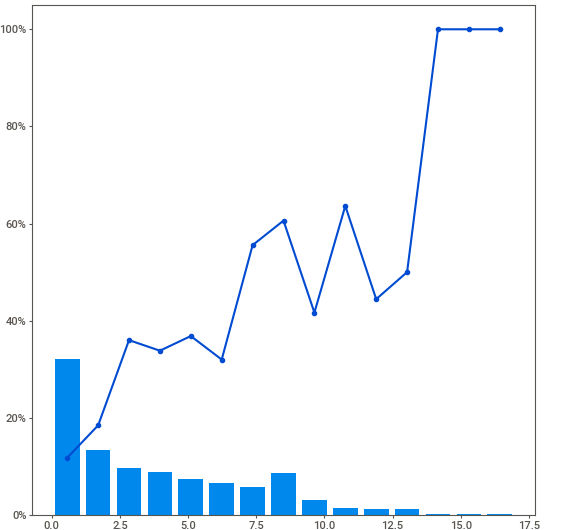
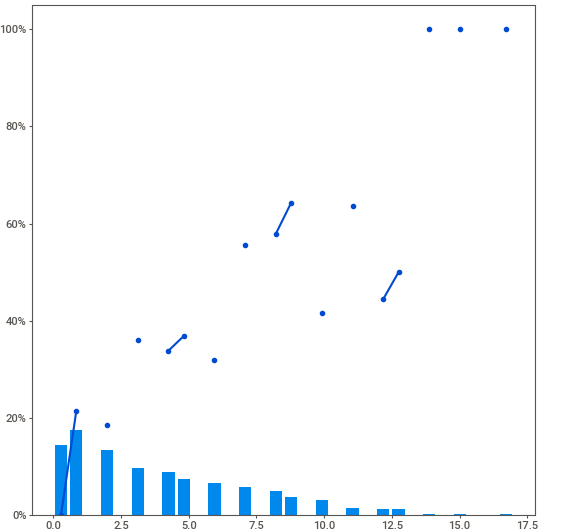
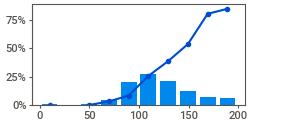
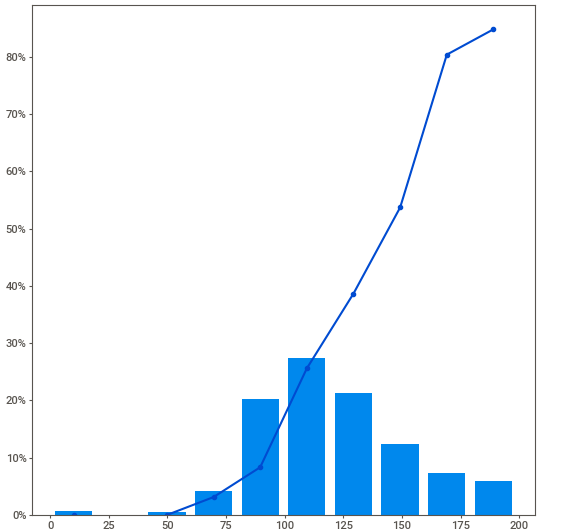
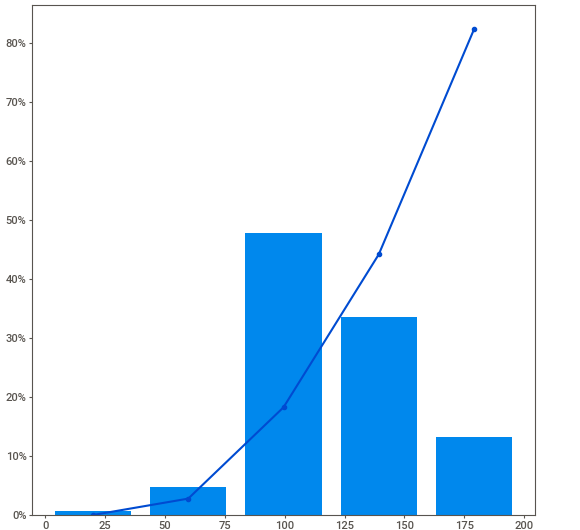
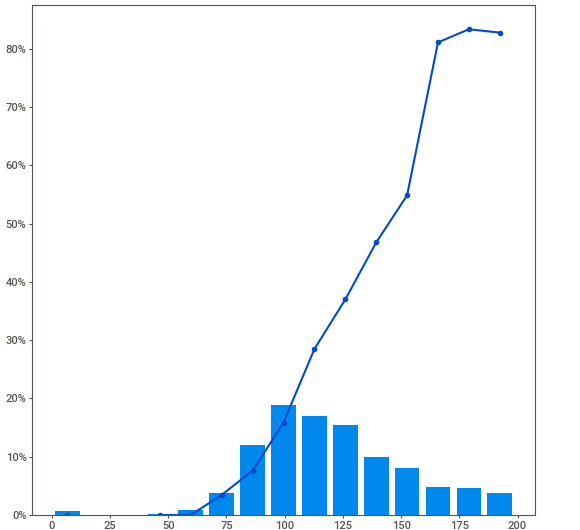
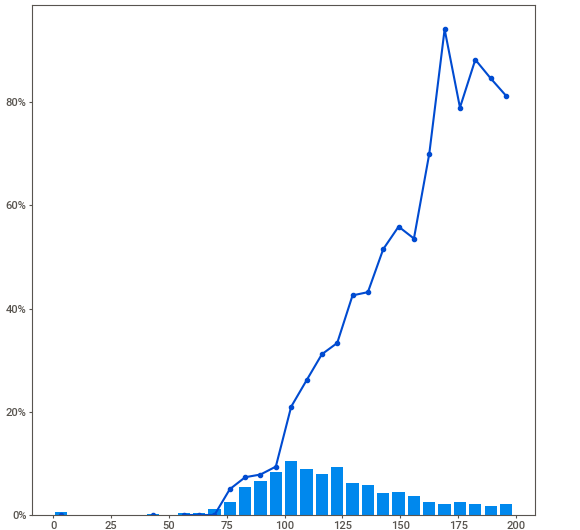
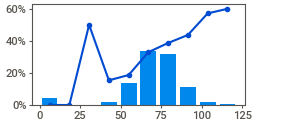
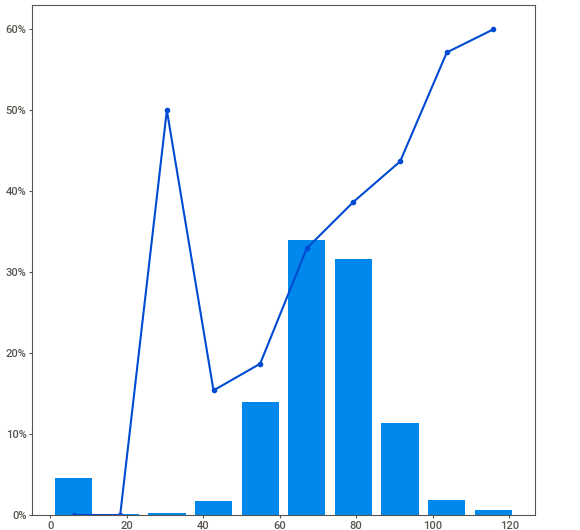
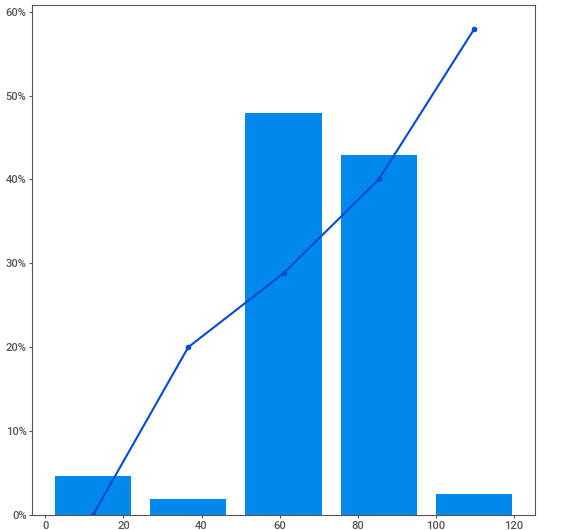
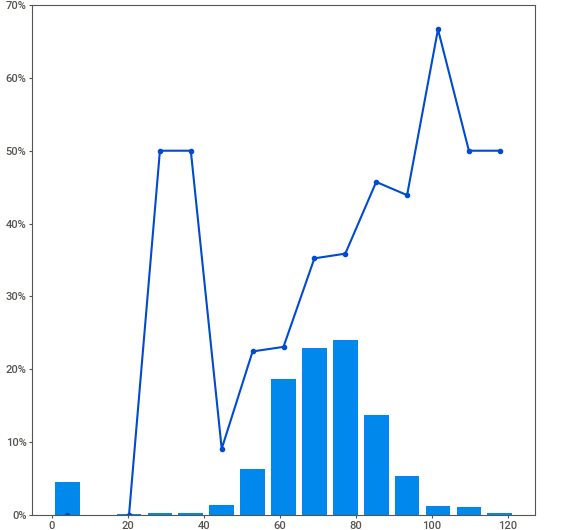
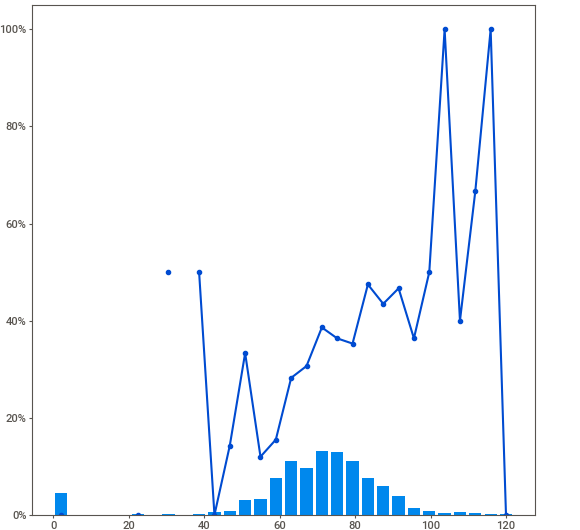
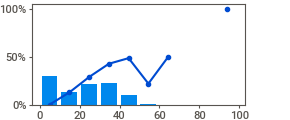
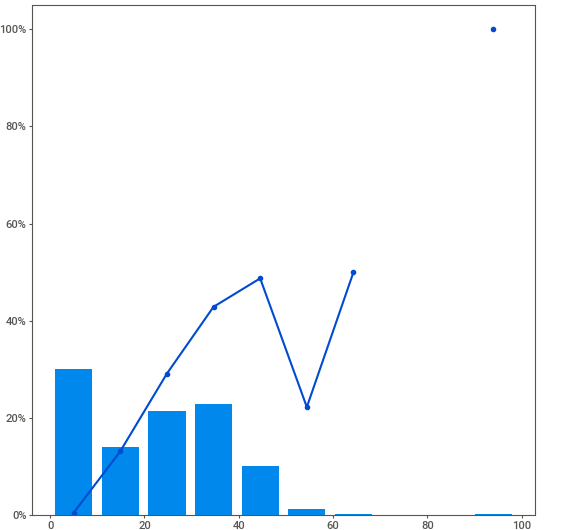
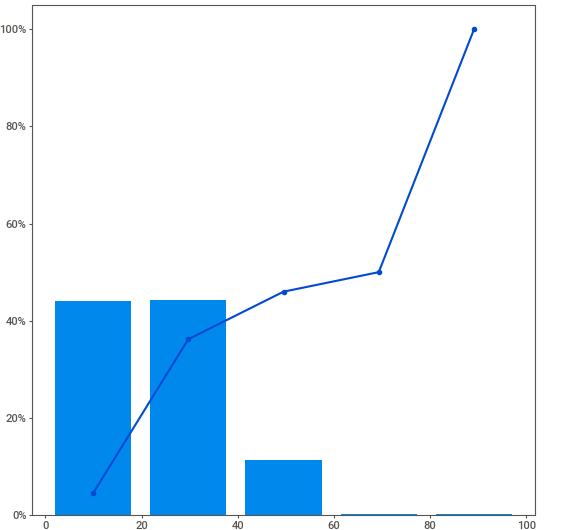
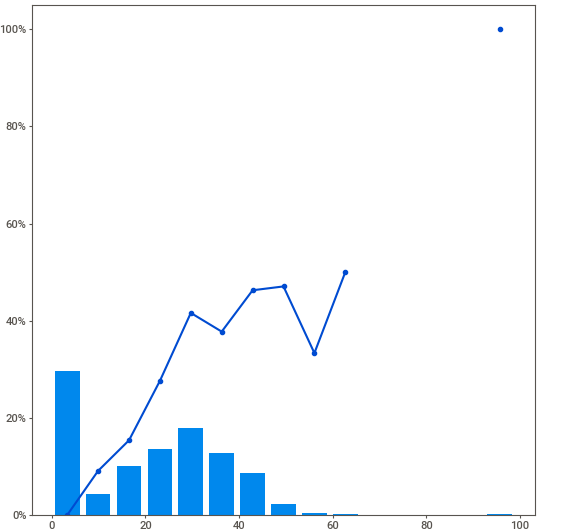
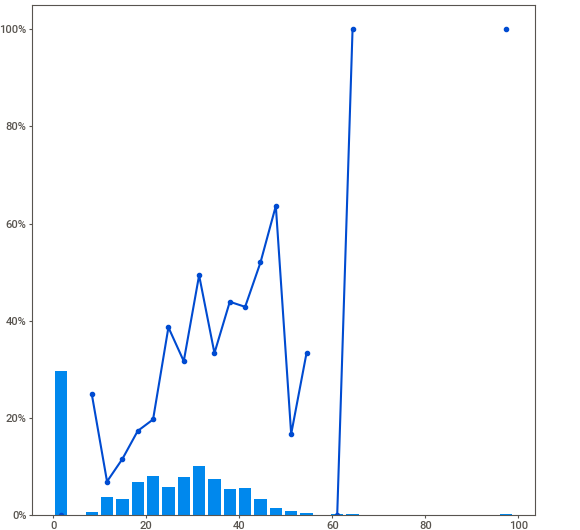
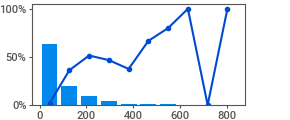
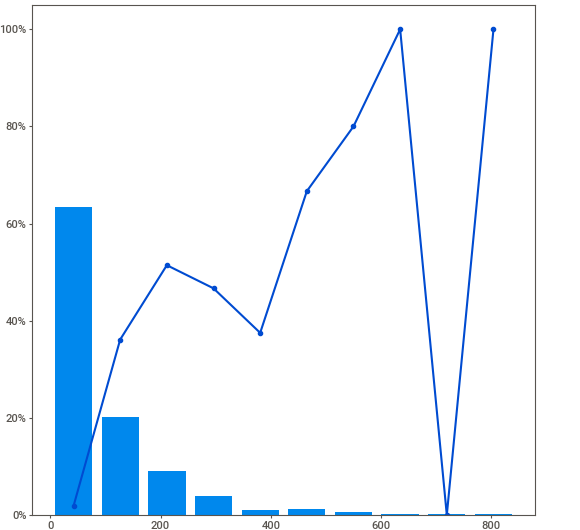
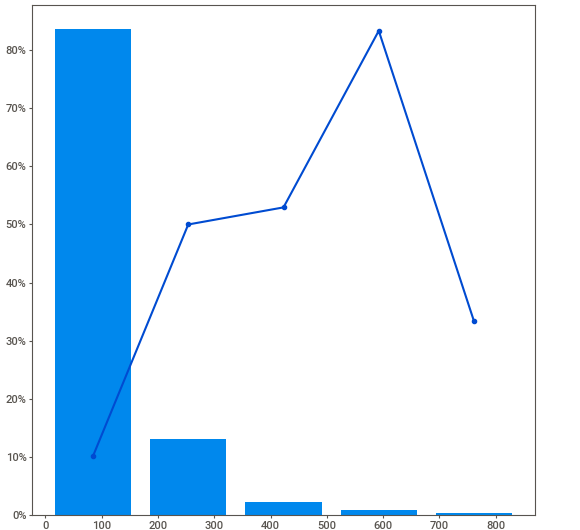
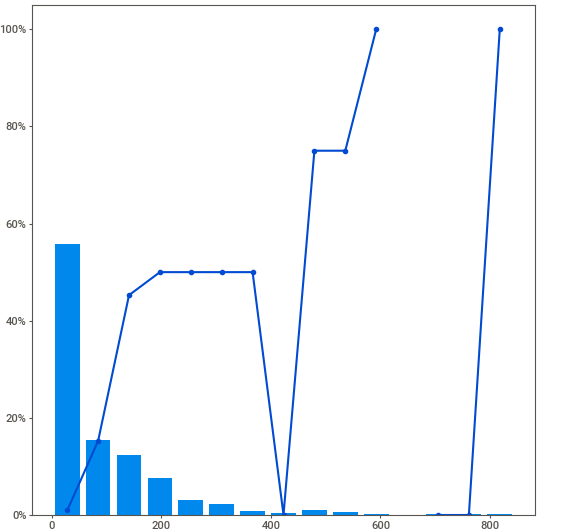
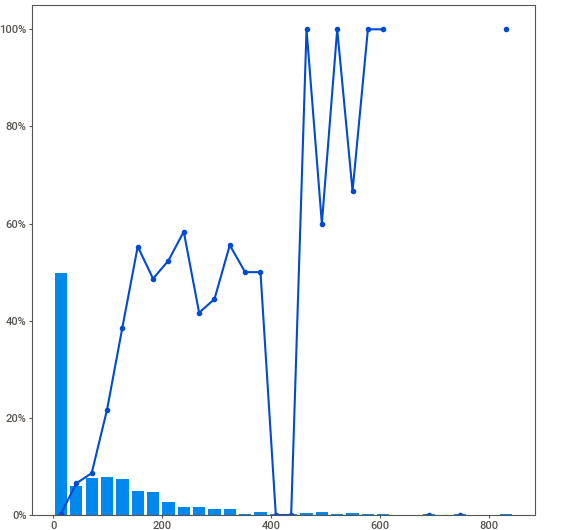
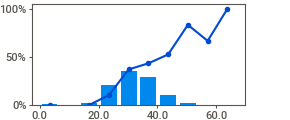
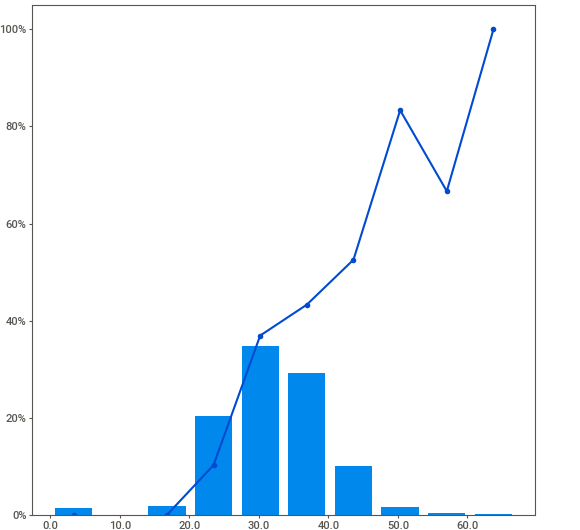
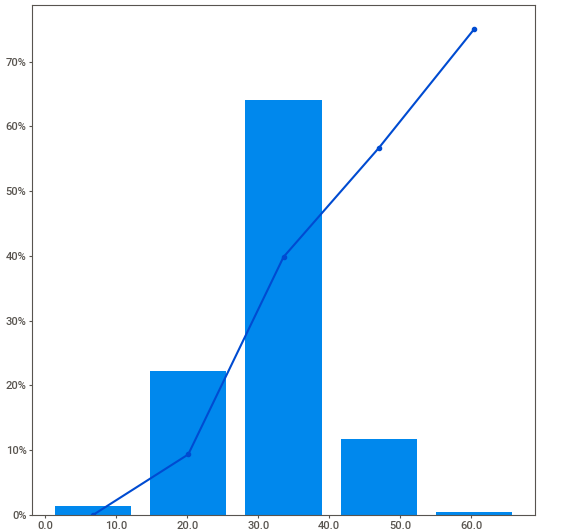
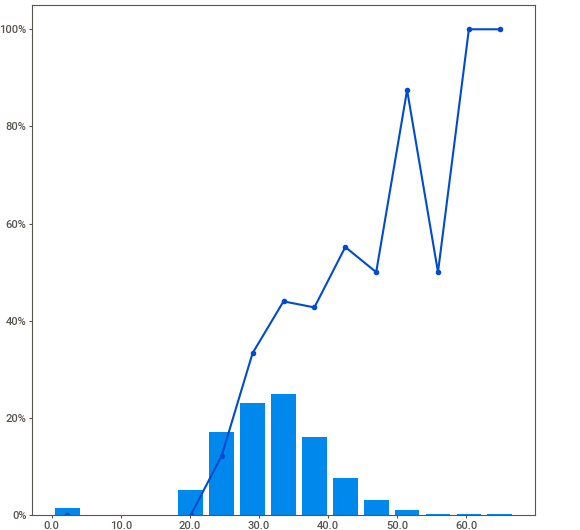
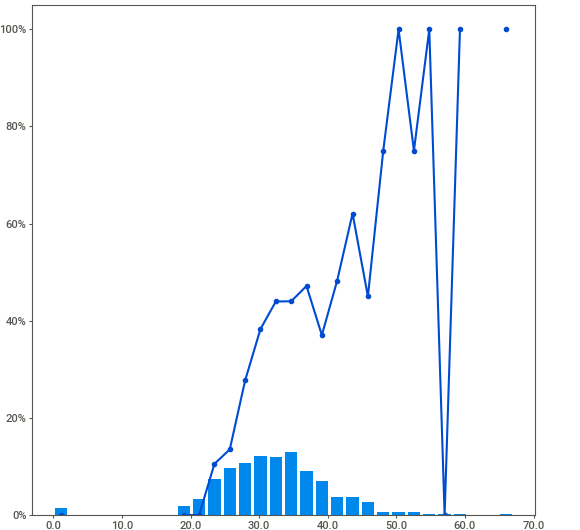
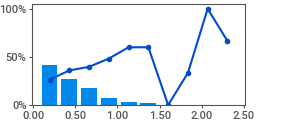
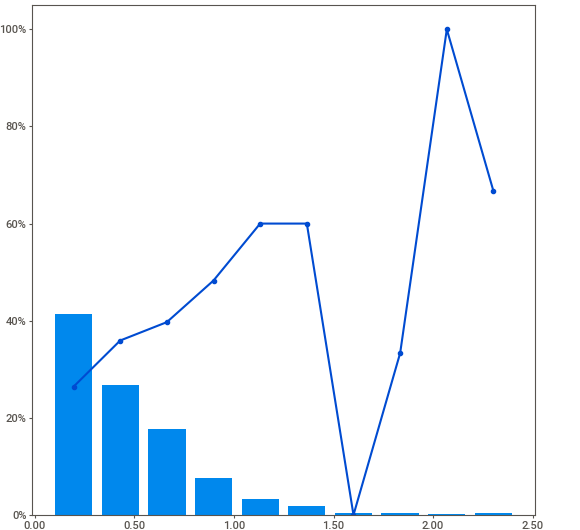
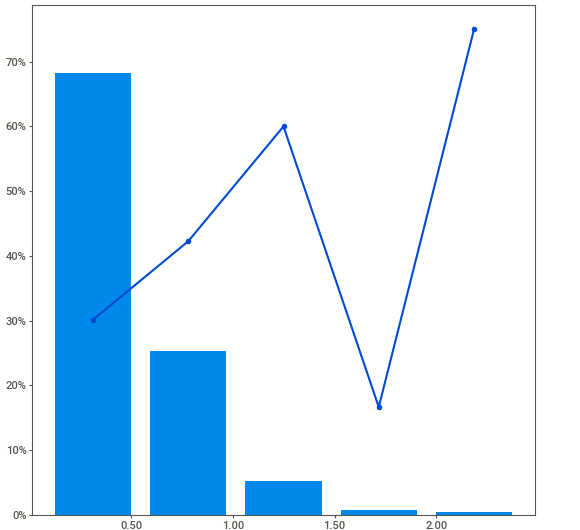
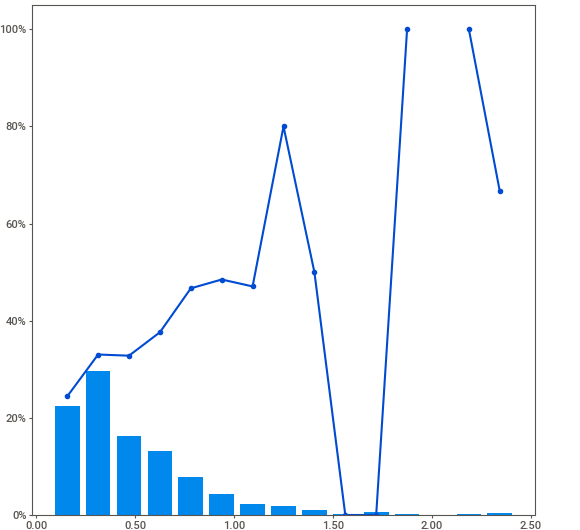
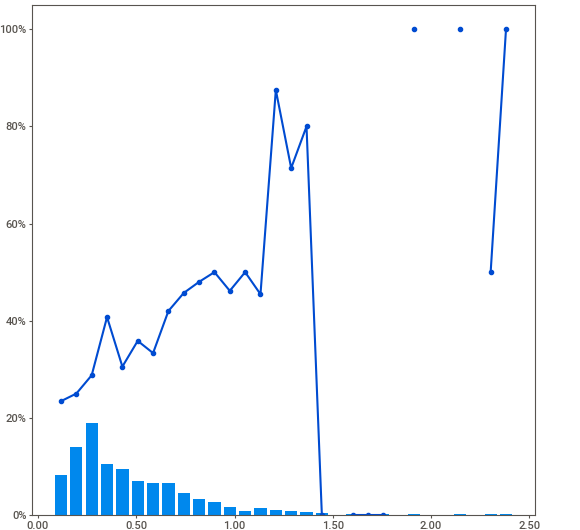
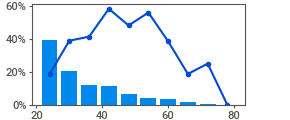
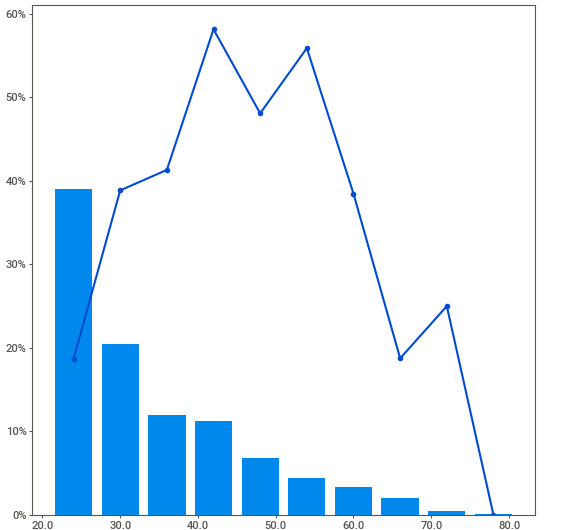
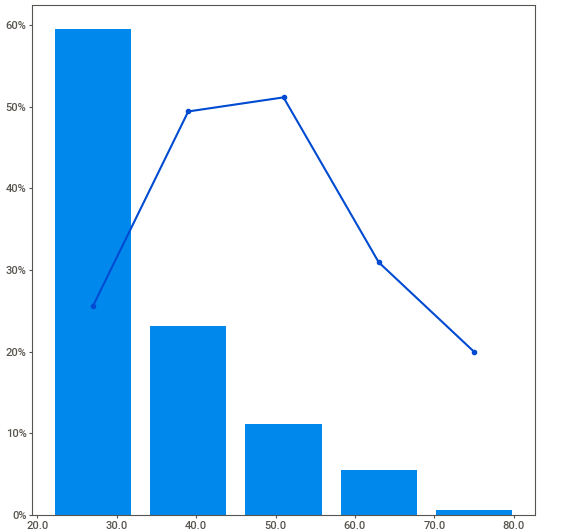
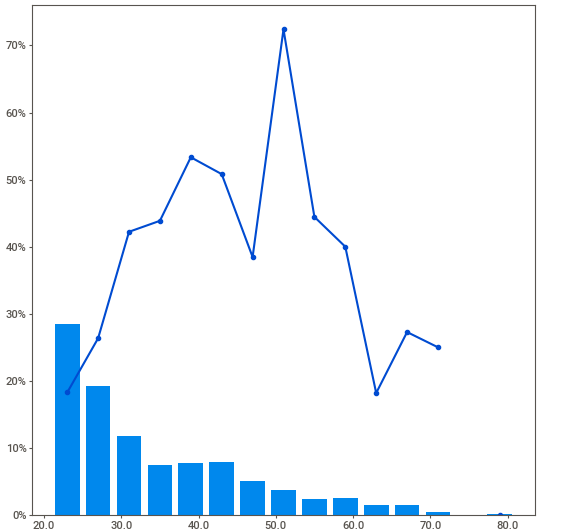
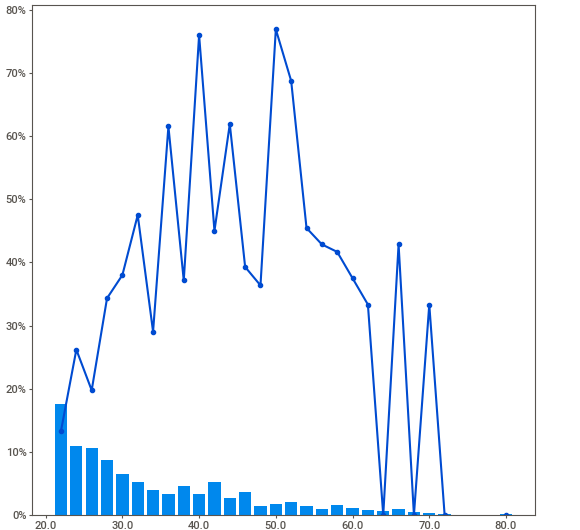
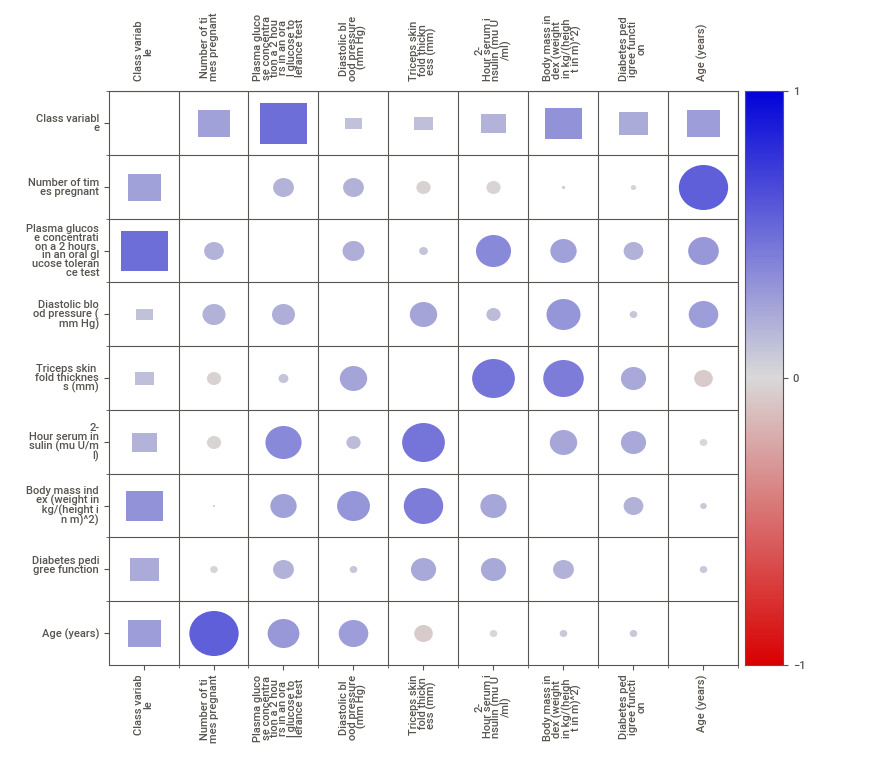
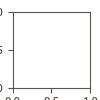

In [ ]:
import sweetviz as sv

reporte = sv.analyze(data, target_feat='Class variable')
reporte.show_notebook()

**Análisis**:

Se observa que la tabla no tiene valores nulos, la variable objetivo tiene un ligero desbalance (65% de los pacientes no tienen diabetes frente a 35% que si lo tienen). La variable objetivo se relaciona más con las variables: concentración de glucosa, índice de masa corporal, edad y número de veces embarazada.

En seguida el análisis específico para cada variable explicativa de la diabetes:

1. `Número de veces embarazada`: Entre más veces la mujer haya sido embarazada aumenta la tasa de casos de diabetes. Lo más común es que una mujer no haya tenido embarazos, sin embargo, observamos que hay un caso con 17 embarazos (esta mujer tiene diabetes).
2. `Concentración de glucosa`: blablablabla

## 3. Configuración PyCaret

Esta función inicializa el entorno de entrenamiento y crea la canalización de transformación. La función de configuración debe llamarse antes de ejecutar cualquier otra función. Toma dos parámetros obligatorios: `data` y `target`. Todos los demás parámetros son opcionales.

In [ ]:
from pycaret import classification
# Puede especificar el session_id para que la división de
# los datos en entrenamiento y testeo permanezca fijo
s = classification.setup(data, target = 'Class variable', session_id=1234)

,Description,Value
0,Session id,1234
1,Target,Class variable
2,Target type,Binary
3,Original data shape,"(768, 9)"
4,Transformed data shape,"(768, 9)"
5,Transformed train set shape,"(537, 9)"
6,Transformed test set shape,"(231, 9)"
7,Numeric features,8
8,Preprocess,True
9,Imputation type,simple


Cuando se ejecuta la configuración, el algoritmo de inferencia de PyCaret inferirá automáticamente los tipos de datos para todas las variables en función de ciertas propiedades.

El tipo de datos debe inferirse correctamente, pero no siempre es así. Para manejar esto, PyCaret muestra un aviso, solicitando la confirmación de los tipos de datos, una vez que ejecuta la configuración. Puede presionar enter si todos los tipos de datos son correctos o escribir quit para salir de la configuración.

Asegurarse de que los tipos de datos sean correctos es realmente importante en PyCaret, ya que realiza automáticamente múltiples tareas de preprocesamiento específicas del tipo que son imprescindibles para los modelos de aprendizaje automático.


Alternativamente, también puede usar los parámetros `numeric_features` y `categorical_features` en la configuración para predefinir los tipos de datos.

## 4. Comparar modelos

Esta función entrena y evalúa el rendimiento de todos los estimadores (modelos) disponibles en la biblioteca de modelos mediante validación cruzada.

El resultado de esta función es una tabla de puntuación con puntuaciones medias validadas de forma cruzada. Se puede acceder a las métricas evaluadas durante CV mediante la función `get_metrics`. Las métricas personalizadas se pueden agregar o eliminar mediante las funciones `add_metric` y `remove_metric`.

In [ ]:
mejor_modelo = classification.compare_models(sort='AUC')

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
gbc,Gradient Boosting Classifier,0.7503,0.8372,0.5827,0.6776,0.6117,0.4326,0.4443,0.4420
lda,Linear Discriminant Analysis,0.7654,0.8289,0.5298,0.7298,0.6075,0.4480,0.4633,0.1240
lr,Logistic Regression,0.7616,0.8273,0.5351,0.7148,0.6048,0.4413,0.4549,0.9370
rf,Random Forest Classifier,0.7597,0.8219,0.5880,0.6920,0.6273,0.4534,0.4623,0.4920
et,Extra Trees Classifier,0.7635,0.8205,0.5673,0.7177,0.6241,0.4561,0.4693,0.3970
lightgbm,Light Gradient Boosting Machine,0.7374,0.8115,0.5944,0.6426,0.6091,0.4143,0.4211,1.2660
xgboost,Extreme Gradient Boosting,0.7225,0.8000,0.5509,0.6269,0.5760,0.3734,0.3819,0.0880
nb,Naive Bayes,0.7430,0.7996,0.5728,0.6489,0.6035,0.4165,0.4210,0.1090
qda,Quadratic Discriminant Analysis,0.7335,0.7946,0.5287,0.6443,0.5757,0.3860,0.3927,0.0640
ada,Ada Boost Classifier,0.7394,0.7805,0.5898,0.6513,0.6095,0.4165,0.4246,0.2650


Processing:   0%|          | 0/65 [00:00<?, ?it/s]

In [ ]:
# Creamos el mejor modelo

mejor_modelo = classification.create_model('gbc')

,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7593,0.8737,0.6316,0.6667,0.6486,0.4658,0.4661
1,0.7593,0.7940,0.6842,0.6500,0.6667,0.4785,0.4788
2,0.6852,0.7729,0.4211,0.5714,0.4848,0.2656,0.2720
3,0.7963,0.8887,0.7895,0.6818,0.7317,0.5689,0.5729
4,0.7778,0.7910,0.6842,0.6842,0.6842,0.5128,0.5128
5,0.7963,0.8977,0.5789,0.7857,0.6667,0.5248,0.5375
6,0.7407,0.8902,0.3158,0.8571,0.4615,0.3357,0.4083
7,0.7736,0.8349,0.5556,0.7143,0.6250,0.4664,0.4740
8,0.7358,0.8365,0.5000,0.6429,0.5625,0.3775,0.3836


Processing:   0%|          | 0/4 [00:00<?, ?it/s]

In [ ]:
print(mejor_modelo)

GradientBoostingClassifier(ccp_alpha=0.0, criterion='friedman_mse', init=None,
                           learning_rate=0.1, loss='log_loss', max_depth=3,
                           max_features=None, max_leaf_nodes=None,
                           min_impurity_decrease=0.0, min_samples_leaf=1,
                           min_samples_split=2, min_weight_fraction_leaf=0.0,
                           n_estimators=100, n_iter_no_change=None,
                           random_state=1234, subsample=1.0, tol=0.0001,
                           validation_fraction=0.1, verbose=0,
                           warm_start=False)


In [ ]:
import pandas as pd
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import cross_val_score

In [ ]:
scores = cross_val_score(mejor_modelo, data.drop('Class variable', axis=1), data ['Class variable'], cv=5)

In [ ]:
import matplotlib.pyplot as plt

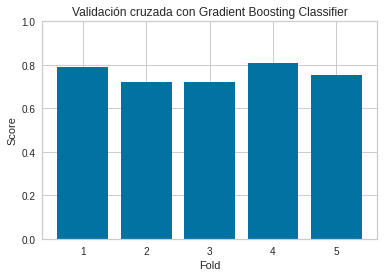

In [ ]:
plt.bar(range(1, 6), scores)
plt.xlabel('Fold')
plt.ylabel('Score')
plt.ylim([0, 1])
plt.title('Validación cruzada con Gradient Boosting Classifier')
plt.show()

In [ ]:
import numpy as np

mean_score = np.mean(scores)
print('Puntaje de validación promedio:', mean_score)

Puntaje de validación promedio: 0.7591715474068416


## 5. Analizar el mejor modelo

Esta función analiza el rendimiento de un modelo entrenado en los datos de testeo. Puede requerir volver a entrenar el modelo en ciertos casos.

In [ ]:
classification.evaluate_model(mejor_modelo)

interactive(children=(ToggleButtons(description='Plot Type:', icons=('',), options=(('Pipeline Plot', 'pipelin…

## 6. Predicciones

In [ ]:
data_test_pred = classification.predict_model(mejor_modelo, raw_score=True)
data_test_pred

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
0,Gradient Boosting Classifier,0.7359,0.7975,0.5802,0.6351,0.6065,0.4084,0.4093


,Number of times pregnant,Plasma glucose concentration a 2 hours in an oral glucose tolerance test,Diastolic blood pressure (mm Hg),Triceps skin fold thickness (mm),2-Hour serum insulin (mu U/ml),Body mass index (weight in kg/(height in m)^2),Diabetes pedigree function,Age (years),Class variable,prediction_label,prediction_score_0,prediction_score_1
610,3,106,54,21,158,30.900000,0.292,24,0,0,0.8830,0.1170
399,3,193,70,31,0,34.900002,0.241,25,1,1,0.1064,0.8936
653,2,120,54,0,0,26.799999,0.455,27,0,0,0.7257,0.2743
421,2,94,68,18,76,26.000000,0.561,21,0,0,0.9916,0.0084
79,2,112,66,22,0,25.000000,0.307,24,0,0,0.9615,0.0385
...,...,...,...,...,...,...,...,...,...,...,...,...
581,6,109,60,27,0,25.000000,0.206,27,0,0,0.9091,0.0909
655,2,155,52,27,540,38.700001,0.240,25,1,0,0.7509,0.2491
170,6,102,82,0,0,30.799999,0.180,36,1,0,0.9013,0.0987
676,9,156,86,0,0,24.799999,0.230,53,1,0,0.8947,0.1053


In [ ]:
data_pred = classification.predict_model(mejor_modelo, data=data, raw_score=True)
data_pred

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
0,Gradient Boosting Classifier,0.8880,0.9394,0.8209,0.8527,0.8365,0.7514,0.7517


,Number of times pregnant,Plasma glucose concentration a 2 hours in an oral glucose tolerance test,Diastolic blood pressure (mm Hg),Triceps skin fold thickness (mm),2-Hour serum insulin (mu U/ml),Body mass index (weight in kg/(height in m)^2),Diabetes pedigree function,Age (years),Class variable,prediction_label,prediction_score_0,prediction_score_1
0,6,148,72,35,0,33.599998,0.627,50,1,1,0.1770,0.8230
1,1,85,66,29,0,26.600000,0.351,31,0,0,0.9365,0.0635
2,8,183,64,0,0,23.299999,0.672,32,1,1,0.1130,0.8870
3,1,89,66,23,94,28.100000,0.167,21,0,0,0.9873,0.0127
4,0,137,40,35,168,43.099998,2.288,33,1,1,0.0657,0.9343
...,...,...,...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.900002,0.171,63,0,0,0.9434,0.0566
764,2,122,70,27,0,36.799999,0.340,27,0,0,0.6026,0.3974
765,5,121,72,23,112,26.200001,0.245,30,0,0,0.9236,0.0764
766,1,126,60,0,0,30.100000,0.349,47,1,1,0.3330,0.6670


In [ ]:
data_test_pred.index

RangeIndex(start=537, stop=768, step=1)

In [ ]:
X_training_data = classification.get_config(variable="X_train")
X_training_data

,Number of times pregnant,Plasma glucose concentration a 2 hours in an oral glucose tolerance test,Diastolic blood pressure (mm Hg),Triceps skin fold thickness (mm),2-Hour serum insulin (mu U/ml),Body mass index (weight in kg/(height in m)^2),Diabetes pedigree function,Age (years)
618,9,112,82,24,0,28.200001,1.282,50
422,0,102,64,46,78,40.599998,0.496,21
683,4,125,80,0,0,32.299999,0.536,27
609,1,111,62,13,182,24.000000,0.138,23
200,0,113,80,16,0,31.000000,0.874,21
...,...,...,...,...,...,...,...,...
113,4,76,62,0,0,34.000000,0.391,25
574,1,143,86,30,330,30.100000,0.892,23
223,7,142,60,33,190,28.799999,0.687,61
36,11,138,76,0,0,33.200001,0.420,35


In [ ]:
y_training_data = classification.get_config(variable="y_train")
y_training_data

618    1
422    0
683    1
609    0
200    0
      ..
113    0
574    0
223    0
36     0
457    0
Name: Class variable, Length: 537, dtype: int8

In [ ]:
import pandas as pd

In [ ]:
Xy_training_data = pd.concat([X_training_data, y_training_data], axis=1)

In [ ]:
data_training_pred = classification.predict_model(mejor_modelo, data=Xy_training_data, raw_score=True)

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
0,Gradient Boosting Classifier,0.9534,0.9906,0.9251,0.9402,0.9326,0.8971,0.8971


##Score Card

In [ ]:
#@title Score Card (análisis de lift)
def score_card_train(Y_real, Y_pred, NumSeg):
    score_card_val = pd.DataFrame()
    if len(Y_pred.shape)==2:
        Y_pred = Y_pred[:,1]
    score_card_val['probabilidad'] = Y_pred.round(5)
    score_card_val['Y'] = Y_real
    score_card_val['decil'] = pd.qcut(score_card_val['probabilidad'], NumSeg, duplicates='drop', precision=6)

    results = score_card_val. \
        groupby(['decil']). \
        agg(Total=pd.NamedAgg('Y', lambda x: x.count()),
            Y1=pd.NamedAgg('Y', lambda x: x.sum()),
            TasaY1=pd.NamedAgg('Y', lambda x: x.mean()),
            prob_mean=pd.NamedAgg('probabilidad', lambda x: x.mean())). \
        reset_index()
    TasaTotal = results['Y1'].sum() / results['Total'].sum()
    results['lift'] = (results['TasaY1'] / TasaTotal).round(2)
    results['Part'] = (results['Total'] / results['Total'].sum())
    results['Y0'] = results['Total'] - results['Y1']

    # Nuevas columnas
    results['TasaY0'] = results['Y0']/results['Total']
    results['TasaAcumY0'] = 1-results['Y0'].shift(1, fill_value=0).cumsum()/results['Y0'].sum()
    results['TasaAcumY1'] = 1-results['Y1'].shift(1, fill_value=0).cumsum()/results['Y1'].sum()
    results['KS'] = (results['TasaAcumY1'] - results['TasaAcumY0']).abs()
    results['Odds'] = results['Y0'] / results['Y1']
    results['OddsAcum'] = results['Y0'].cumsum() / results['Y1'].cumsum()
    results['paraROC'] = (-results['TasaAcumY1'].diff()*results['TasaAcumY0'].rolling(2).sum()).shift(-1,fill_value=0)
    results.loc[len(results)-1, 'paraROC'] = results.loc[len(results)-1, 'TasaAcumY1'] * results.loc[len(results)-1, 'TasaAcumY0']
    results['paraGini'] = (-results['Part'].diff()*results['TasaAcumY1'].rolling(2).sum()).shift(-1,fill_value=0)
    results.loc[len(results)-1, 'paraGini'] = results.loc[len(results)-1, 'Part'] * results.loc[len(results)-1, 'TasaAcumY1']
    results = results[['decil', 'Total', 'Part',
                       'Y0', 'TasaY0', 'TasaAcumY0',
                       'Y1',  'TasaY1', 'TasaAcumY1',
                       'KS', 'Odds', 'OddsAcum',
                       'lift', 'paraROC', 'paraGini', 'prob_mean']]

    # Nuevo: Exporta métricas generales
    metricas = {'lift_growth': (results['lift'].diff()[1:]>0).mean(),
                'lift_last': results['lift'].iloc[-1],
                'KS': results['KS'].max(),
                'Gini': abs(results['paraGini'].sum()-1),
                'ROC': 1-results['paraROC'].sum()/2,
                'AR': 1-results['paraROC'].sum(),
                'OddsMax': results['Odds'].max(),
                'OddsMin': results['Odds'].min()
               }

    cortes = NumSeg-2
    conteo = 0
    lista_xg = []
    lista_xg.append(-1)
    for i in results['decil']:
        if conteo <= cortes:
            lista_xg.append(i.right)
        else:
            lista_xg.append(1)
        conteo = conteo + 1
    puntos_corte = lista_xg

    return results, metricas, lista_xg

def score_card_test(Y_real, Y_pred, deciles):
    score_card_val = pd.DataFrame()
    if len(Y_pred.shape)==2:
        Y_pred = Y_pred[:,1]
    score_card_val['probabilidad'] = Y_pred.round(5)
    score_card_val['Y'] = Y_real
    score_card_val['decil'] = pd.cut(score_card_val['probabilidad'], deciles,precision=6, duplicates='drop')

    results = score_card_val. \
        groupby(['decil']). \
        agg(Total=pd.NamedAgg('Y', lambda x: x.count()),
            Y1=pd.NamedAgg('Y', lambda x: x.sum()),
            TasaY1=pd.NamedAgg('Y', lambda x: x.mean()),
            prob_mean=pd.NamedAgg('probabilidad', lambda x: x.mean())). \
        reset_index()
    TasaTotal = results['Y1'].sum() / results['Total'].sum()
    results['lift'] = (results['TasaY1'] / TasaTotal).round(2)
    results['Part'] = (results['Total'] / results['Total'].sum())
    results['Y0'] = results['Total'] - results['Y1']

     # Nuevas columnas
    results['TasaY0'] = results['Y0']/results['Total']
    results['TasaAcumY0'] = 1-results['Y0'].shift(1, fill_value=0).cumsum()/results['Y0'].sum()
    results['TasaAcumY1'] = 1-results['Y1'].shift(1, fill_value=0).cumsum()/results['Y1'].sum()
    results['KS'] = (results['TasaAcumY1'] - results['TasaAcumY0']).abs()
    results['Odds'] = results['Y0'] / results['Y1']
    results['OddsAcum'] = results['Y0'].cumsum() / results['Y1'].cumsum()
    results['paraROC'] = (-results['TasaAcumY1'].diff()*results['TasaAcumY0'].rolling(2).sum()).shift(-1,fill_value=0)
    results.loc[len(results)-1, 'paraROC'] = results.loc[len(results)-1, 'TasaAcumY1'] * results.loc[len(results)-1, 'TasaAcumY0']
    results['paraGini'] = (-results['Part'].diff()*results['TasaAcumY1'].rolling(2).sum()).shift(-1,fill_value=0)
    results.loc[len(results)-1, 'paraGini'] = results.loc[len(results)-1, 'Part'] * results.loc[len(results)-1, 'TasaAcumY1']
    results = results[['decil', 'Total', 'Part',
                       'Y0', 'TasaY0', 'TasaAcumY0',
                       'Y1',  'TasaY1', 'TasaAcumY1',
                       'KS', 'Odds', 'OddsAcum',
                       'lift', 'paraROC', 'paraGini', 'prob_mean']]

    # Nuevo: Exporta métricas generales
    metricas = {'lift_growth': (results['lift'].diff()[1:]>0).mean(),
                'lift_last': results['lift'].iloc[-1],
                'KS': results['KS'].max(),
                'Gini': abs(results['paraGini'].sum()-1),
                'ROC': 1-results['paraROC'].sum()/2,
                'AR': 1-results['paraROC'].sum(),
                'OddsMax': results['Odds'].max(),
                'OddsMin': results['Odds'].min()
               }

    return results, metricas

In [ ]:
results, metricas, deciles = score_card_train(data_training_pred['Class variable'], data_training_pred['prediction_score_1'], 10)
results

,decil,Total,Part,Y0,TasaY0,TasaAcumY0,Y1,TasaY1,TasaAcumY1,KS,Odds,OddsAcum,lift,paraROC,paraGini,prob_mean
0,"(0.005599, 0.01968]",54,0.100559,54,1.000000,1.000000,0,0.000000,1.000000,0.000000,inf,inf,0.00,-0.000000,-0.000000,0.014372
1,"(0.01968, 0.0393]",54,0.100559,54,1.000000,0.845714,0,0.000000,1.000000,0.154286,inf,inf,0.00,-0.000000,0.003724,0.028765
2,"(0.0393, 0.06896]",53,0.098696,53,1.000000,0.691429,0,0.000000,1.000000,0.308571,inf,inf,0.00,-0.000000,-0.003724,0.052360
3,"(0.06896, 0.10562]",54,0.100559,54,1.000000,0.540000,0,0.000000,1.000000,0.460000,inf,inf,0.00,-0.000000,-0.000000,0.085369
4,"(0.10562, 0.189]",54,0.100559,52,0.962963,0.385714,2,0.037037,1.000000,0.614286,26.000000,133.500000,0.11,0.006662,0.003704,0.143802
5,"(0.189, 0.34006]",53,0.098696,50,0.943396,0.237143,3,0.056604,0.989305,0.752162,16.666667,63.400000,0.16,0.005317,-0.003655,0.256915
6,"(0.34006, 0.58442]",54,0.100559,29,0.537037,0.094286,25,0.462963,0.973262,0.878976,1.160000,11.533333,1.33,0.014133,0.003376,0.471280
7,"(0.58442, 0.7702]",53,0.098696,4,0.075472,0.011429,49,0.924528,0.839572,0.828144,0.081633,4.430380,2.65,0.002995,-0.002639,0.654755
8,"(0.7702, 0.89462]",54,0.100559,0,0.000000,0.000000,54,1.000000,0.577540,0.577540,0.000000,2.631579,2.87,0.000000,-0.000000,0.832983
9,"(0.89462, 0.9862]",54,0.100559,0,0.000000,0.000000,54,1.000000,0.288770,0.288770,0.000000,1.871658,2.87,0.000000,0.029038,0.941078


In [ ]:
results, metricas = score_card_test(data_test_pred['Class variable'], data_test_pred['prediction_score_1'], deciles)
results

,decil,Total,Part,Y0,TasaY0,TasaAcumY0,Y1,TasaY1,TasaAcumY1,KS,Odds,OddsAcum,lift,paraROC,paraGini,prob_mean
0,"(-1.0, 0.01968]",15,0.064935,15,1.000000,1.000000,0,0.000000,1.000000,0.000000,inf,inf,0.00,-0.000000,-0.060606,0.011940
1,"(0.01968, 0.0393]",22,0.095238,19,0.863636,0.900000,3,0.136364,1.000000,0.100000,6.333333,11.333333,0.39,0.061975,0.025493,0.028655
2,"(0.0393, 0.06896]",19,0.082251,19,1.000000,0.773333,0,0.000000,0.962963,0.189630,inf,17.666667,0.00,-0.000000,-0.058361,0.053947
3,"(0.06896, 0.10562]",26,0.112554,22,0.846154,0.646667,4,0.153846,0.962963,0.316296,5.500000,10.714286,0.44,0.056626,0.056865,0.090069
4,"(0.10562, 0.189]",19,0.082251,12,0.631579,0.500000,7,0.368421,0.913580,0.413580,1.714286,6.214286,1.05,0.079506,-0.082892,0.143358
5,"(0.189, 0.34006]",30,0.129870,21,0.700000,0.420000,9,0.300000,0.827160,0.407160,2.333333,4.695652,0.86,0.077778,-0.060125,0.254480
6,"(0.34006, 0.58442]",39,0.168831,23,0.589744,0.280000,16,0.410256,0.716049,0.436049,1.437500,3.358974,1.17,0.080329,0.085511,0.465041
7,"(0.58442, 0.7702]",23,0.099567,9,0.391304,0.126667,14,0.608696,0.518519,0.391852,0.642857,2.641509,1.74,0.033416,0.003741,0.668074
8,"(0.7702, 0.89462]",22,0.095238,6,0.272727,0.066667,16,0.727273,0.345679,0.279012,0.375000,2.115942,2.07,0.018436,0.012827,0.846891
9,"(0.89462, 1.0]",16,0.069264,4,0.250000,0.026667,12,0.750000,0.148148,0.121481,0.333333,1.851852,2.14,0.003951,0.010261,0.940044


In [ ]:
!pip install binclass-tools

In [ ]:
import bctools as bc

In [ ]:
area_under_PR = bc.curve_PR_plot(true_y = data_test_pred['Class variable'],
                                 predicted_proba = data_test_pred['prediction_score_1'],
                                 beta = 1)

area_under_PR[0]

In [ ]:
threshold_step = 0.05
curve_type = 'kde' #'kde' is the default value, can also be set to 'normal'
bc.predicted_proba_density_curve_plot(true_y = data_test_pred['Class variable'],
                                      predicted_proba = data_test_pred['prediction_score_1'],
                                      threshold_step = threshold_step,
                                      curve_type = curve_type)

In [ ]:
# set params for the train dataset
threshold_step = 0.05
optimize_threshold = None
currency = '$'
# It takes as input, for each class, a float or a list of floats.
# Lists must have coherent lenghts
# Ejemplo: FP: cuesta $10 equivocarnos en pacientes que realmente no estan enfermos,
# FN: Cuesta $5 equivocarnos en pacientes que estan realmente enfermos (nosotros decimos que estan sanos)
# TP: Pacientes que están realmente enfermos y en el modelo decimos que están enfermos, acertar tiene un beneficio, por lo tanto se le da un valor negativo, para este caso $-15
train_cost_dict = bc.get_cost_dict(TN = 0, FP = 10, FN = 5, TP = -15)

In [ ]:
confusion_matrix = bc.confusion_matrix_plot(
    true_y = data_test_pred['Class variable'],
    predicted_proba = data_test_pred['prediction_score_1'],
    threshold_step = threshold_step,
    cost_dict = train_cost_dict,
    # optimize_threshold = optimize_threshold,
    currency = currency,
    # random_state = 123,
    title = 'Interactive Confusion Matrix for the Training Set');

In [ ]:
confusion_matrix[0]

## 7. Guardar y cargar modelo

In [ ]:
classification.save_model(mejor_modelo, 'mi_mejor_modelo')

Transformation Pipeline and Model Successfully Saved


(Pipeline(memory=Memory(location=None),
          steps=[('numerical_imputer',
                  TransformerWrapper(exclude=None,
                                     include=['Number of times pregnant',
                                              'Plasma glucose concentration a 2 '
                                              'hours in an oral glucose '
                                              'tolerance test',
                                              'Diastolic blood pressure (mm Hg)',
                                              'Triceps skin fold thickness (mm)',
                                              '2-Hour serum insulin (mu U/ml)',
                                              'Body mass index (weight in '
                                              'kg/(height in m)^2)',
                                              'Diabetes pedigre...
                                             criterion='friedman_mse', init=None,
                                      

In [ ]:
modelo_cargado = classification.load_model('mi_mejor_modelo')
print(modelo_cargado)

Transformation Pipeline and Model Successfully Loaded
Pipeline(memory=FastMemory(location=/tmp/joblib),
         steps=[('clean_column_names',
                 TransformerWrapper(exclude=None, include=None,
                                    transformer=CleanColumnNames(match='[\\]\\[\\,\\{\\}\\"\\:]+'))),
                ('numerical_imputer',
                 TransformerWrapper(exclude=None,
                                    include=['Number of times pregnant',
                                             'Plasma glucose concentration a 2 '
                                             'hours in an oral glucose '
                                             'tolerance test',
                                             'Diastol...
                                            criterion='friedman_mse', init=None,
                                            learning_rate=0.1, loss='deviance',
                                            max_depth=3, max_features=None,
                   

In [ ]:
# Guardamos el pipeline
# import pickle
from joblib import dump, load


pipeline = classification.get_leaderboard().iloc[0]['Model']
# pipeline = classification.get_config('pipeline')

# with open('pipe2.joblib', 'wb') as f:
#   # pickle.dump(pipeline, f)
#   dump(pipeline, 'pipe2.joblib')

dump(pipeline, 'pipe3.joblib')

Processing:   0%|          | 0/2 [00:00<?, ?it/s]

['pipe3.joblib']

In [ ]:
# Cargamos el pipeline y realizamos pronósticos
with open('pipe.pkl', 'rb') as f:
  pipe = pickle.load(f)

pipe.predict(data.drop(columns=['Class variable']))

array([1, 0, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 0, 0,
       1, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0, 1,
       1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0,
       1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0,
       1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1,
       1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1,
       0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0,
       0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 1,
       1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0,
       0, 1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0,
       1, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 0, 1, 0,
       0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1,

https://getindata.com/blog/pycaret-bigqueryml-inference-engine-fastest-way-train-deploy-machine-learning-model/